<a href="https://colab.research.google.com/github/Hasini-uni/DAVlab/blob/main/lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('/content/Student_Marks[1].csv')

print(df)

    number_courses  time_study   Marks
0                3       4.508  19.202
1                4       0.096   7.734
2                4       3.133  13.811
3                6       7.909  53.018
4                8       7.811  55.299
..             ...         ...     ...
95               6       3.561  19.128
96               3       0.301   5.609
97               4       7.163  41.444
98               7       0.309  12.027
99               3       6.335  32.357

[100 rows x 3 columns]


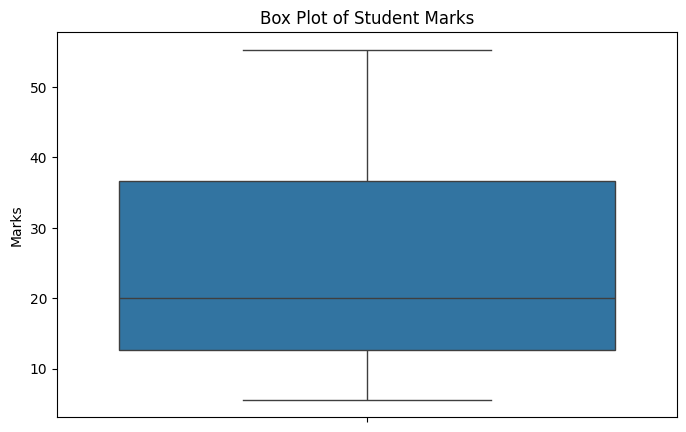

In [2]:
# Create a box plot to visualize the distribution of marks
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])

# Add title and axis label
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")

# Display the plot
plt.show()


In [4]:
# Calculate the first and third quartiles
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

# Display the quartile values
print("Q1 =", Q1)
print("Q3 =", Q3)
# Calculating the Interquartile Range
IQR = Q3 - Q1
# Displaying the IQR value
print("IQR =", IQR)



Q1 = 12.633
Q3 = 36.676249999999996
IQR = 24.043249999999997


In [5]:
# Calculate the lower and upper limits for outlier detection
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Display the limits
print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)


Lower Limit = -23.431874999999994
Upper Limit = 72.74112499999998


In [6]:
# Select values below the lower limit or above the upper limit
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

# Display the detected outliers
print("Outliers detected using IQR:")
print(outliers_iqr)


Outliers detected using IQR:
Empty DataFrame
Columns: [number_courses, time_study, Marks]
Index: []


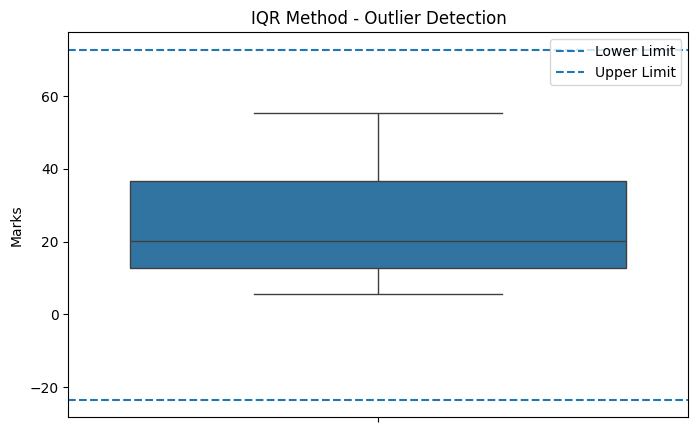

In [7]:
# Create a box plot to show the outlier limits
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])

# Draw horizontal lines for the lower and upper limits
plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

# Add title and legend
plt.title("IQR Method - Outlier Detection")
plt.legend()

# Display the plot
plt.show()


In [8]:

# Replace values below and above the limits with the boundary values
df['Marks_IQR_Capped'] = df['Marks'].clip(
    lower=lower_limit,
    upper=upper_limit
)

# Display original and capped marks
print(df[['Marks', 'Marks_IQR_Capped']])


     Marks  Marks_IQR_Capped
0   19.202            19.202
1    7.734             7.734
2   13.811            13.811
3   53.018            53.018
4   55.299            55.299
..     ...               ...
95  19.128            19.128
96   5.609             5.609
97  41.444            41.444
98  12.027            12.027
99  32.357            32.357

[100 rows x 2 columns]


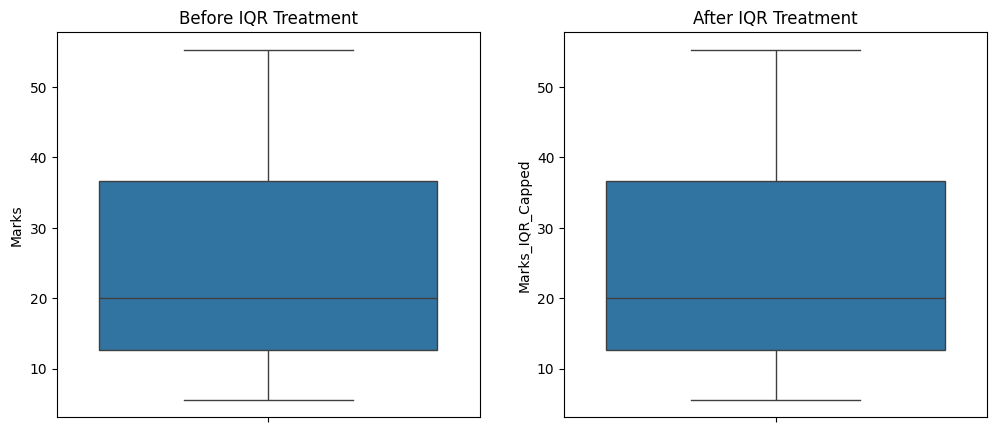

In [9]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

# Display both plots
plt.show()


In [10]:
# Calculate the Z-score for each student's marks
df['Z_score'] = stats.zscore(df['Marks'])

# Display marks and their Z-scores
print(df[['Marks', 'Z_score']])


     Marks   Z_score
0   19.202 -0.365901
1    7.734 -1.170425
2   13.811 -0.744100
3   53.018  2.006422
4   55.299  2.166442
..     ...       ...
95  19.128 -0.371092
96   5.609 -1.319502
97  41.444  1.194461
98  12.027 -0.869254
99  32.357  0.556973

[100 rows x 2 columns]


In [11]:
# Identify values whose absolute Z-score is greater than 3
z_outliers = df[abs(df['Z_score']) > 3]

# Display the detected outliers
print("Outliers detected using Z-score:")
print(z_outliers)

# Create a column indicating whether each value is an outlier
df['Z_Outlier'] = abs(df['Z_score']) > 3

# Display the outlier status
print(df[['Marks', 'Z_score', 'Z_Outlier']])


Outliers detected using Z-score:
Empty DataFrame
Columns: [number_courses, time_study, Marks, Marks_IQR_Capped, Z_score]
Index: []
     Marks   Z_score  Z_Outlier
0   19.202 -0.365901      False
1    7.734 -1.170425      False
2   13.811 -0.744100      False
3   53.018  2.006422      False
4   55.299  2.166442      False
..     ...       ...        ...
95  19.128 -0.371092      False
96   5.609 -1.319502      False
97  41.444  1.194461      False
98  12.027 -0.869254      False
99  32.357  0.556973      False

[100 rows x 3 columns]


In [13]:
# Calculate the mean and standard deviation of marks
mean = df['Marks'].mean()
std = df['Marks'].std()

# Calculate the lower and upper Z-score limits
lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

# Display the limits
print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)


# Replace extreme values with the calculated boundary values
df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit)

# Display original and capped marks
print(df[['Marks', 'Marks_Z_Capped']])

Lower Z-score limit = -18.560905712273932
Upper Z-score limit = 67.39628571227392
     Marks  Marks_Z_Capped
0   19.202          19.202
1    7.734           7.734
2   13.811          13.811
3   53.018          53.018
4   55.299          55.299
..     ...             ...
95  19.128          19.128
96   5.609           5.609
97  41.444          41.444
98  12.027          12.027
99  32.357          32.357

[100 rows x 2 columns]


     Marks  Marks_IQR_Capped  Marks_Z_Capped
0   19.202            19.202          19.202
1    7.734             7.734           7.734
2   13.811            13.811          13.811
3   53.018            53.018          53.018
4   55.299            55.299          55.299
..     ...               ...             ...
95  19.128            19.128          19.128
96   5.609             5.609           5.609
97  41.444            41.444          41.444
98  12.027            12.027          12.027
99  32.357            32.357          32.357

[100 rows x 3 columns]


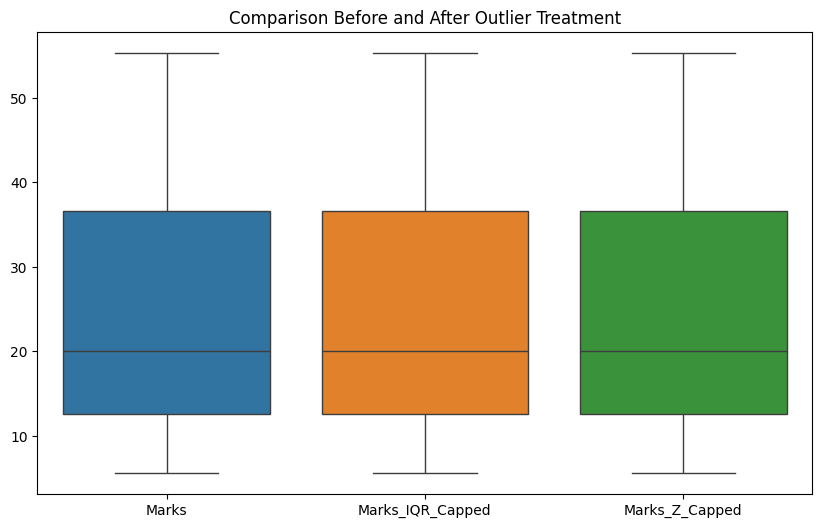

In [14]:
# Compare original marks with IQR-capped and Z-score-capped marks
print(df[['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']])

# Create a box plot to compare all three versions
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[
    ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
])

plt.title("Comparison Before and After Outlier Treatment")
plt.show()
